In [1]:
try:

  import torch
  import torchvision
  assert int(torchvision.__version__.split(".")[1]) >= 12 , "torch version should be 1.12+"
  assert int(torchvision.__version__.split(".")[1]) >=13, "torchvision version should be 1.13+"
  print(f"torch version:{torch.__version__}")
  print(f"torchvision version:{torchvision.__version__}")

except:
  print(f"[INFO] torch/torchvision versions  not as required. Installing nightly versions as required")
  !pip3 install -U torch torchvision torchaudio --extra-index-url https://download.pytorch.org/whl/cu113
  import torch
  import torchvision
  print(f"torch version:{torch.__version__}")
  print(f"torchvision version:{torchvision.__version__}")




torch version:2.11.0+cu128
torchvision version:0.26.0+cu128


In [2]:
# Continue with regular imports
import matplotlib.pyplot as plt
import torch
import torchvision

from torch import nn
from torchvision import transforms

# Try to get torchinfo, install it if it doesn't work
try:
    from torchinfo import summary
except:
    print("[INFO] Couldn't find torchinfo... installing it.")
    !pip install -q torchinfo
    from torchinfo import summary

# Try to import the going_modular directory, download it from GitHub if it doesn't work
try:
    from going_modular.going_modular import data_setup, engine
except:
    # Get the going_modular scripts
    print("[INFO] Couldn't find going_modular scripts... downloading them from GitHub.")
    !git clone https://github.com/mrdbourke/pytorch-deep-learning
    !mv pytorch-deep-learning/going_modular .
    !rm -rf pytorch-deep-learning
    from going_modular.going_modular import data_setup, engine

[INFO] Couldn't find torchinfo... installing it.
[INFO] Couldn't find going_modular scripts... downloading them from GitHub.
Cloning into 'pytorch-deep-learning'...
remote: Enumerating objects: 4410, done.
remote: Counting objects: 100% (10/10), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 4410 (delta 5), reused 2 (delta 2), pack-reused 4400 (from 2)
Receiving objects: 100% (4410/4410), 764.18 MiB | 17.56 MiB/s, done.
Resolving deltas: 100% (2661/2661), done.
Updating files: 100% (248/248), done.


In [3]:
#setup device agnostic code

device  = "cuda" if torch.cuda.is_available() else "cpu"
device


'cuda'

Get the data

In [4]:
import os
import zipfile

from pathlib import Path

import requests

# Setup path to data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

# If the image folder doesn't exist, download it and prepare it...
if image_path.is_dir():
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)

    # Download pizza, steak, sushi data
    with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        print("Downloading pizza, steak, sushi data...")
        f.write(request.content)

    # Unzip pizza, steak, sushi data
    with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
        print("Unzipping pizza, steak, sushi data...")
        zip_ref.extractall(image_path)

    # Remove .zip file
    os.remove(data_path / "pizza_steak_sushi.zip")

Did not find data/pizza_steak_sushi directory, creating one...
Unzipping pizza, steak, sushi data...


In [5]:
#creating the paths to our training and test directories
train_dir = image_path /"train"
test_dir  = image_path /"test"

train_dir

print(os.path.exists("data/pizza_steak_sushi/train"))

True


2. Create Datasets and DataLoaders

Since we've downloaded the going_modular directory, we can use the data_setup.py script we created in section 05. PyTorch Going Modular to prepare and setup our DataLoaders.

But since we'll be using a pretrained model from torchvision.models, there's a specific transform we need to prepare our images first.

2.1 Creating a transform for torchvision.models (manual creation)

In [6]:
#create a transform pipeline manually (required torchvision > 0.13)

manual_transforms = transforms.Compose([transforms.Resize((224,224)), # 1. Reshape all images to 224x224 (though some models may require different sizes)
                                        transforms.ToTensor(), # 2. Turn image values to between 0 & 1
                                        transforms.Normalize(mean=[0.485, 0.456, 0.406], # 3. A mean of [0.485, 0.456, 0.406] (across each colour channel)
                                                             std=[0.229, 0.224, 0.225]) # 4. A standard deviation of [0.229, 0.224, 0.225] (across each colour channel),
                                                             ])

Now we've got a manually created series of transforms ready to prepare our images, let's create training and testing DataLoaders.

In [7]:
#creating training and testing dataloaders as well as class names

train_dataloader , test_dataloader , class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                                  test_dir=test_dir,
                                                                                  transform=manual_transforms, # resize, convert images to between 0 & 1 and normalize them
                                                                                  batch_size=32, # set mini-batch size to 32
                                                                                  )

train_dataloader , test_dataloader , class_names

(<torch.utils.data.dataloader.DataLoader at 0x7ba2f8429d90>,
 ['pizza', 'steak', 'sushi'])

2.2 Creating a transform for torchvision.models (auto creation)

In [8]:
#get a set of pretrained weights

weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT #default = best availanle model on pretraining on ImageNet
weights

EfficientNet_B0_Weights.IMAGENET1K_V1

In [9]:
#get the transforms used to create our pretrained  weights
auto_transforms  = weights.transforms()
auto_transforms

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)

In [10]:
#creating training and testing dataloaders as well  as class names with auto-transforms

train_dataloaders , test_dataloaders , class_names  = data_setup.create_dataloaders(train_dir=train_dir,
                                                                                    test_dir = test_dir,
                                                                                    transform = auto_transforms,
                                                                                    batch_size=32 #set the mini batch size to 32
                                                                                    )

train_dataloaders , test_dataloaders , class_names

(<torch.utils.data.dataloader.DataLoader at 0x7ba2f842adb0>,
 ['pizza', 'steak', 'sushi'])

3. Getting a pretrained model

In [11]:
#setup the model with pretrained weights and send it to the target device

weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT #default  = best available weight
model = torchvision.models.efficientnet_b0(weights=weights).to(device)

model


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 180MB/s]


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [12]:
#print a summary for using torch info

summary(model=model,
        input_size=(32,3,224,224), #make sure this is input_size not input_shape
        col_names=["input_size","output_size","num_params","trainable"],
        col_width =20,
        row_settings=["var_names"]
        )


Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 1000]           --                   True
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   True
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   True
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   864                  True
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   64                   True
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 16, 112

In [13]:
#freeze all the base layers in the feature section of models (the feature extractor0 by setting requires_grad = False)

for param in model.features.parameters():
  param.requires_grad = False

In [14]:
#set the manual seed

torch.manual_seed(42)
torch.cuda.manual_seed(4)

#get the length of the class names (one output for each class )
output_shape = len(class_names)

#recreate classifier layer and seed it to the target device
model.classifier = nn.Sequential(
    torch.nn.Dropout(p=0.2, inplace=True),
    torch.nn.Linear(in_features=1280,
                    out_features=output_shape,
                    bias=True, )).to(device)

In [15]:
#do a summary after freezing the layer and changing ouput classifer layer

summary(model,
        input_size=(32,3,224,224),#make sure this is input size
        verbose=0,
        col_names=["input_size","output_size","num_params","trainable"],
        col_width=20,
        row_settings=["var_names"]
        )

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

In [16]:
#define the loss and optimizer

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(),lr=0.001)

In [17]:
#lets train the model with transfer learning


torch.manual_seed(42)
torch.cuda.manual_seed(42)

#start the timer
from timeit import default_timer as timer
train_start_time = timer()

#setup training and save the results

results = engine.train(model=model,
                       train_dataloader=train_dataloader,
                       test_dataloader = test_dataloader,
                       loss_fn = loss_fn,
                       optimizer=optimizer,
                       epochs=5,
                       device=device)

#stop the train time and print how long it took
train_time_end = timer()
print(f"[INFO]The train time taken by model:{train_time_end - train_start_time:.3f}")


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0895 | train_acc: 0.4414 | test_loss: 0.9202 | test_acc: 0.5085
Epoch: 2 | train_loss: 0.8682 | train_acc: 0.7734 | test_loss: 0.8022 | test_acc: 0.7434
Epoch: 3 | train_loss: 0.7771 | train_acc: 0.7812 | test_loss: 0.7399 | test_acc: 0.7737
Epoch: 4 | train_loss: 0.7249 | train_acc: 0.7422 | test_loss: 0.6472 | test_acc: 0.8864
Epoch: 5 | train_loss: 0.6445 | train_acc: 0.7812 | test_loss: 0.6244 | test_acc: 0.8968
[INFO]The train time taken by model:8.968


[INFO] could not find helper functions, downloading them from GitHub


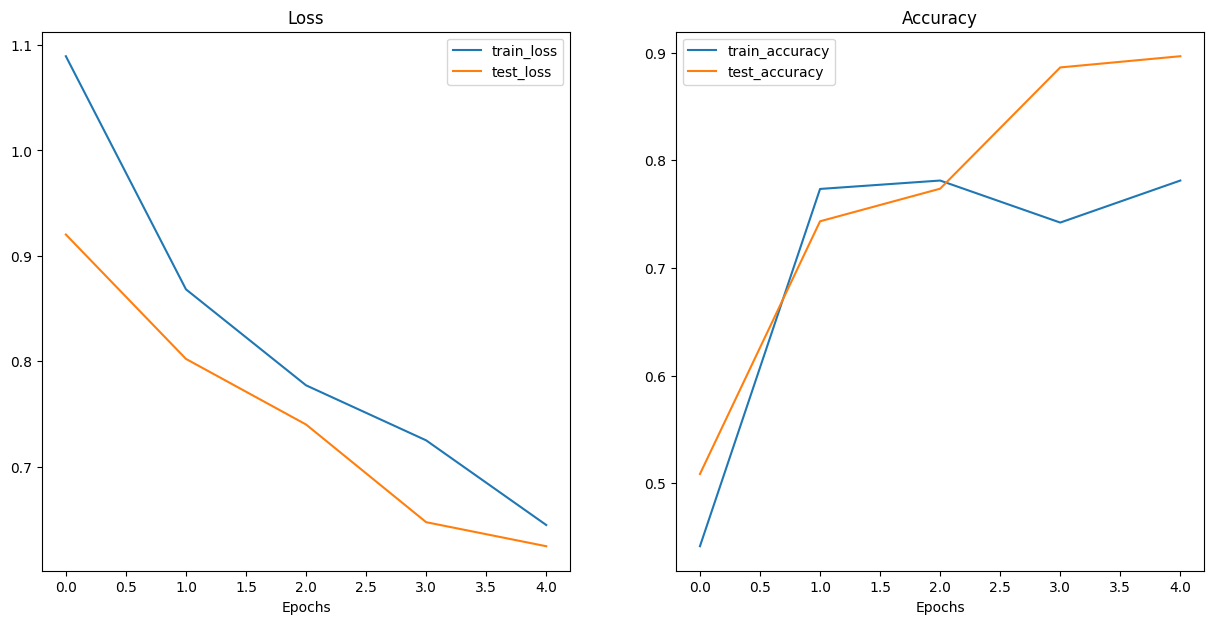

In [18]:
#get the plot_loss_curves function from helper_functions.py

try:
  from helper_functions import plot_Loss_curves

except:
  print(f"[INFO] could not find helper functions, downloading them from GitHub")
  with open ("helper_functions.py","wb") as f:
    import requests
    request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
    f.write(request.content)

  from helper_functions import plot_loss_curves

#plot the loss curves of our model
plot_loss_curves(results)

In [39]:
from typing import List , Tuple

from PIL import Image

#1. take a trained model , class names , image path , image size , a transforms and target device

def pred_and_plot_image(model: torch.nn.Module,
                        image_path: str,
                        class_names: List[str],
                        image_size:Tuple[int,int]=(224,224),
                        transform: torchvision.transforms=None,
                        device:torch.device=device):

  #open image
  image = Image.open(image_path)

  #create transform for the image it it doesnt exits
  if transform is not None:
    image_transform = transform

  else:
    image_transform = transforms.Compose([transforms.Resize(image_size),
                                          transforms.ToTensor(),
                                          transforms.Normalize(mean=[0.485,0.456,0.406],
                                                              std=[0.229, 0.224, 0.225])])

  ###predict on image ###

  #3. make sure the model is on right device
  model.to(device)

  #4. turn model evaluation mode and model inference  mode
  model.eval()
  with torch.inference_mode():
    #5. transform the image and add a dimension for inference on image (adding batch size on image data)
    transformed_image = image_transform(image).unsqueeze(dim=0)

    #6. make prediction on the image with extra dimension  and send that to the target device
    target_image_pred = model(transformed_image.to(device))

  #7. convert-logits -->> prediction probabilities(using torch.softmax() for multiclass classification)

  target_image_pred_prob = torch.softmax(target_image_pred, dim=1)

  #8. convert prediction probabilities into prediction labels
  target_image_pred_labels = torch.argmax(target_image_pred_prob, dim=1)

  #9. plot image with predicted image and probability
  plt.figure()
  plt.imshow(image)
  plt.title(f"Pred:{class_names[target_image_pred_labels]} , Prob:{target_image_pred_prob.max():.3f}")
  plt.axis(False)


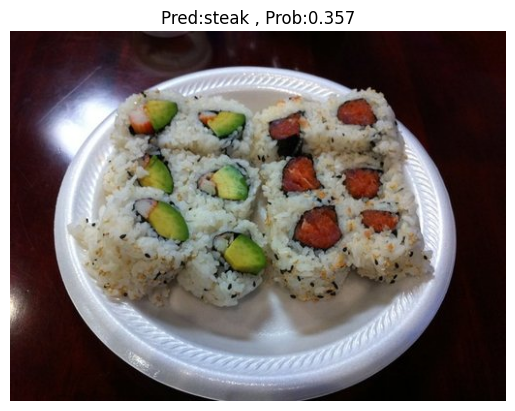

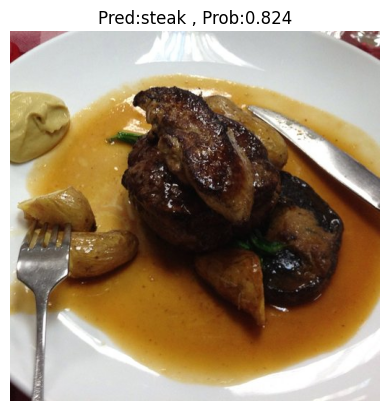

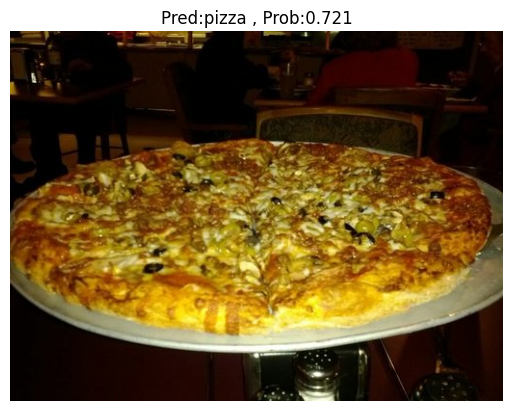

In [40]:
import random

num_images_list = 3
test_image_path_list = list(Path(test_dir).glob("*/*.jpg"))  #get the list of all the images from path list
test_image_path_sample = random.sample(population=test_image_path_list, #go through all the test image path
                                       k=num_images_list) # randomlt select 'k' image path to pred and plot


#make predictions on and plot the images
for test_image_path in test_image_path_sample:
  pred_and_plot_image(model=model,
                      image_path=test_image_path,
                      class_names=class_names,
                      transform=auto_transforms,
                      image_size=(224,224))

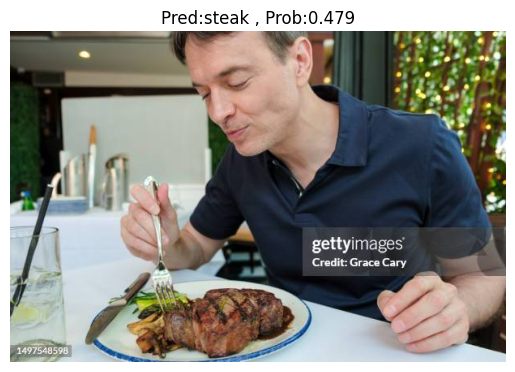

In [41]:
#prediction on the custom image

#setup custom image path
data_path = Path("data/")
custom_path = data_path/ "pred_image.jpg"

#predict on custom image
pred_and_plot_image(model=model,
                    image_path = custom_path,
                    class_names=class_names)